Number of waste bins: 18
Number of vehicles: 3
Vehicle capacity: 20
Total waste demand: 36
Iteration 20: Best Distance = 89.02 km
Iteration 40: Best Distance = 89.02 km
Iteration 60: Best Distance = 89.02 km
Iteration 80: Best Distance = 89.02 km
Iteration 100: Best Distance = 89.02 km

========== FINAL RESULTS ==========

Vehicle 1: [0, np.int64(12), np.int64(9), np.int64(14), np.int64(4), np.int64(6), np.int64(17), np.int64(1), np.int64(13), np.int64(5), 0]
Waste collected: 20
Route distance: 38.79 km

Vehicle 2: [0, np.int64(2), np.int64(18), np.int64(7), np.int64(16), np.int64(11), np.int64(15), np.int64(3), np.int64(8), np.int64(10), 0]
Waste collected: 16
Route distance: 50.23 km

Vehicle 3: [0, 0]
Waste collected: 0
Route distance: 0 km

Total bins collected: 18
Total distance: 89.02 km
Estimated time: 213.65 minutes
Estimated fuel cost: Rs. 3115.72


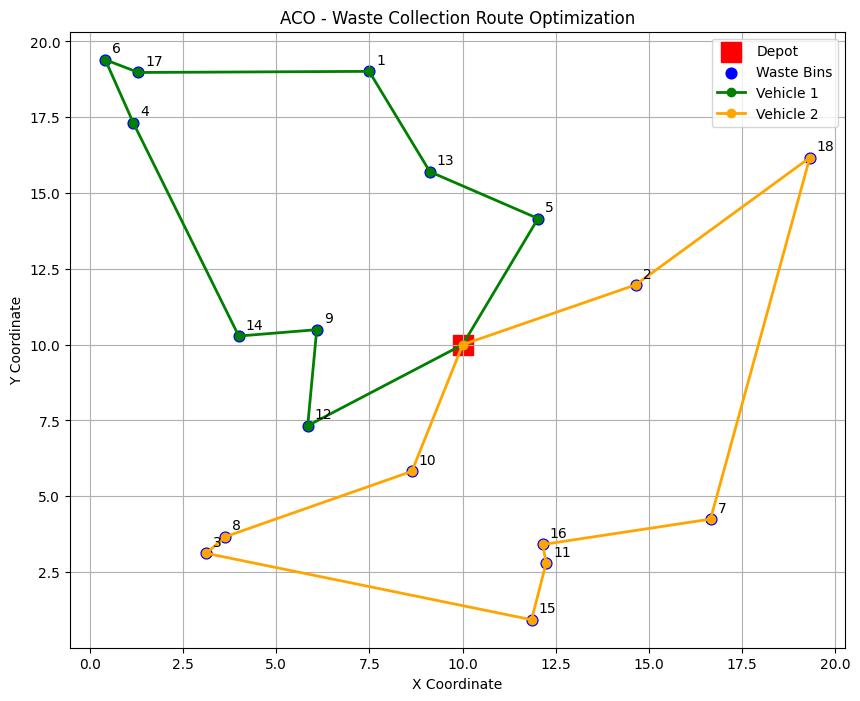

In [4]:

# ============================================================
# ANT COLONY OPTIMIZATION FOR WASTE COLLECTION ROUTE
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import random

# ------------------------------------------------------------
# 1. INITIALIZE PARAMETERS
# ------------------------------------------------------------

np.random.seed(42)
random.seed(42)

NUM_VEHICLES = 3
VEHICLE_CAPACITY = 20

NUM_ANTS = 40
NUM_ITERATIONS = 100

ALPHA = 1.0
BETA = 3.0
RHO = 0.5
Q = 100.0

AVERAGE_SPEED = 25
FUEL_RATE = 0.35
FUEL_PRICE = 100

# ------------------------------------------------------------
# 2. CREATE DEPOT AND WASTE COLLECTION POINTS
# ------------------------------------------------------------

depot = np.array([10.0, 10.0])

NUM_BINS = 18

bin_coordinates = np.random.uniform(
    0, 20, size=(NUM_BINS, 2)
)

bin_demands = np.random.randint(
    1, 4, size=NUM_BINS
)

all_coordinates = np.vstack([
    depot,
    bin_coordinates
])

N = len(all_coordinates)

print("Number of waste bins:", NUM_BINS)
print("Number of vehicles:", NUM_VEHICLES)
print("Vehicle capacity:", VEHICLE_CAPACITY)
print("Total waste demand:", sum(bin_demands))

# ------------------------------------------------------------
# 3. CREATE DISTANCE MATRIX
# ------------------------------------------------------------

distance_matrix = np.zeros((N, N))

for i in range(N):
    for j in range(N):

        distance_matrix[i][j] = np.linalg.norm(
            all_coordinates[i] - all_coordinates[j]
        )

# ------------------------------------------------------------
# 4. HELPER FUNCTIONS
# ------------------------------------------------------------

def calculate_route_distance(route):

    if len(route) == 0:
        return 0

    full_route = [0] + route + [0]

    total_distance = 0

    for i in range(len(full_route) - 1):

        total_distance += distance_matrix[
            full_route[i]
        ][
            full_route[i + 1]
        ]

    return total_distance


def calculate_total_distance(routes):

    return sum(
        calculate_route_distance(route)
        for route in routes
    )


def calculate_route_load(route):

    return sum(
        bin_demands[node - 1]
        for node in route
    )

# ------------------------------------------------------------
# 5. 2-OPT LOCAL SEARCH
# ------------------------------------------------------------

def two_opt(route):

    best_route = route.copy()

    best_distance = calculate_route_distance(best_route)

    improved = True

    while improved:

        improved = False

        for i in range(len(best_route) - 1):

            for j in range(i + 1, len(best_route)):

                new_route = (
                    best_route[:i]
                    + best_route[i:j+1][::-1]
                    + best_route[j+1:]
                )

                new_distance = calculate_route_distance(
                    new_route
                )

                if new_distance < best_distance:

                    best_route = new_route
                    best_distance = new_distance
                    improved = True

    return best_route

# ------------------------------------------------------------
# 6. ANT COLONY OPTIMIZATION
# ------------------------------------------------------------

def ant_colony_optimization():

    pheromone = np.ones((N, N))

    heuristic = 1 / (distance_matrix + 1e-10)

    np.fill_diagonal(heuristic, 0)

    best_routes = None
    best_distance = float("inf")

    for iteration in range(NUM_ITERATIONS):

        all_ant_routes = []
        all_ant_distances = []

        for ant in range(NUM_ANTS):

            unvisited = set(range(1, N))

            routes = []

            for vehicle in range(NUM_VEHICLES):

                current_node = 0
                current_load = 0
                route = []

                while unvisited:

                    feasible_bins = [
                        node for node in unvisited
                        if current_load + bin_demands[node - 1]
                        <= VEHICLE_CAPACITY
                    ]

                    if not feasible_bins:
                        break

                    probabilities = []

                    for node in feasible_bins:

                        tau = pheromone[current_node][node] ** ALPHA

                        eta = heuristic[current_node][node] ** BETA

                        probabilities.append(tau * eta)

                    probabilities = np.array(probabilities)

                    probabilities /= probabilities.sum()

                    next_node = np.random.choice(
                        feasible_bins,
                        p=probabilities
                    )

                    route.append(next_node)

                    current_load += bin_demands[next_node - 1]

                    current_node = next_node

                    unvisited.remove(next_node)

                routes.append(route)

            if unvisited:
                continue

            routes = [
                two_opt(route)
                for route in routes
            ]

            total_distance = calculate_total_distance(routes)

            all_ant_routes.append(routes)
            all_ant_distances.append(total_distance)

            if total_distance < best_distance:

                best_distance = total_distance

                best_routes = [
                    route.copy()
                    for route in routes
                ]

        # PHEROMONE EVAPORATION

        pheromone *= (1 - RHO)

        # PHEROMONE UPDATE

        for routes, distance in zip(
            all_ant_routes,
            all_ant_distances
        ):

            deposit = Q / distance

            for route in routes:

                full_route = [0] + route + [0]

                for i in range(len(full_route) - 1):

                    a = full_route[i]
                    b = full_route[i + 1]

                    pheromone[a][b] += deposit
                    pheromone[b][a] += deposit

        if (iteration + 1) % 20 == 0:

            print(
                f"Iteration {iteration + 1}: "
                f"Best Distance = {best_distance:.2f} km"
            )

    if best_routes is None:
        raise ValueError("No feasible vehicle allocation found.")

    return best_routes, best_distance

# ------------------------------------------------------------
# 7. RUN ACO ALGORITHM
# ------------------------------------------------------------

best_routes, best_distance = ant_colony_optimization()

# ------------------------------------------------------------
# 8. DISPLAY FINAL RESULTS
# ------------------------------------------------------------

print("\n========== FINAL RESULTS ==========")

for i, route in enumerate(best_routes, 1):

    print(f"\nVehicle {i}: {[0] + route + [0]}")

    print("Waste collected:", calculate_route_load(route))

    print(
        "Route distance:",
        round(calculate_route_distance(route), 2),
        "km"
    )

total_time = best_distance / AVERAGE_SPEED * 60

fuel_cost = best_distance * FUEL_RATE * FUEL_PRICE

print("\nTotal bins collected:", NUM_BINS)

print("Total distance:", round(best_distance, 2), "km")

print("Estimated time:", round(total_time, 2), "minutes")

print("Estimated fuel cost: Rs.", round(fuel_cost, 2))

# ------------------------------------------------------------
# 9. VISUALIZE OPTIMIZED ROUTES
# ------------------------------------------------------------

def plot_routes(routes):

    plt.figure(figsize=(10, 8))

    plt.scatter(
        depot[0],
        depot[1],
        color="red",
        marker="s",
        s=200,
        label="Depot"
    )

    plt.scatter(
        bin_coordinates[:, 0],
        bin_coordinates[:, 1],
        color="blue",
        s=60,
        label="Waste Bins"
    )

    colors = ["green", "orange", "purple"]

    for i, route in enumerate(routes):

        if not route:
            continue

        full_route = [0] + route + [0]

        x = [all_coordinates[node][0] for node in full_route]

        y = [all_coordinates[node][1] for node in full_route]

        plt.plot(
            x,
            y,
            marker="o",
            color=colors[i],
            linewidth=2,
            label=f"Vehicle {i + 1}"
        )

    for i, (x, y) in enumerate(bin_coordinates):

        plt.annotate(
            str(i + 1),
            (x, y),
            xytext=(5, 5),
            textcoords="offset points"
        )

    plt.title("ACO - Waste Collection Route Optimization")

    plt.xlabel("X Coordinate")
    plt.ylabel("Y Coordinate")

    plt.legend()
    plt.grid(True)
    plt.show()


plot_routes(best_routes)
